## Utility functions

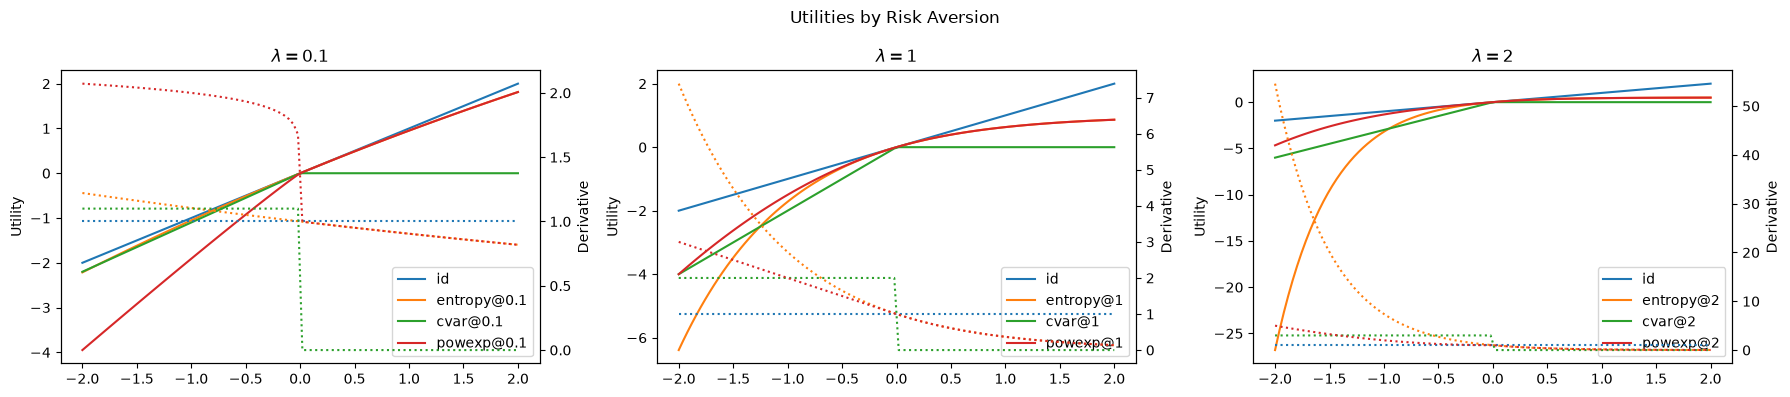

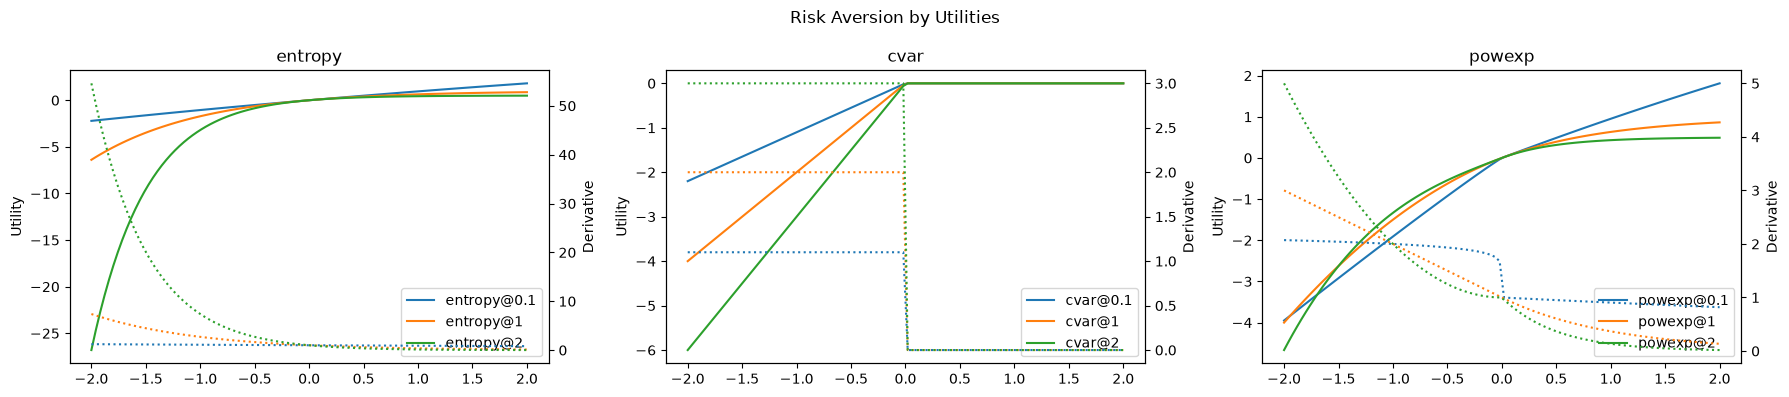

In [5]:

from cdxcore.dynaplot import figure
from openqai.core.nn.jax.utility import jax_utility
import numpy as np

def plot_utilities():

    utilities = [ "id", "entropy", "cvar", "powexp" ]
    lamndas   = [ 0.1, 1, 2. ]

    x  = np.linspace(-2., 2., 100)
    with figure("Utilities by Risk Aversion", row_size=4, col_size=6, columns=None ) as fig:
        for lmbda in lamndas:
            ax = fig.add_subplot(fr"$\lambda={lmbda:.2g}$")
            ax2 = ax.twinx()
            for utility in utilities:
                u, deriv, label = jax_utility(utility, lmbda)
                ax.plot( x, u(x), "-", label=label)
                ax2.plot( x, deriv(x), ":", label=label)
            ax.set_ylabel("Utility")
            ax2.set_ylabel("Derivative")
            ax.legend(loc="lower right")
    with figure("Risk Aversion by Utilities", row_size=4, col_size=6, columns=None ) as fig:
        for utility in utilities:
            if utility == "id":
                continue
            ax = fig.add_subplot(utility)
            ax2 = ax.twinx()
            for lmbda in lamndas:
                u, deriv, label = jax_utility(utility, lmbda)
                ax.plot( x, u(x), "-", label=label)
                ax2.plot( x, deriv(x), ":", label=label)
            ax.set_ylabel("Utility")
            ax2.set_ylabel("Derivative")
            ax.legend(loc="lower right")

plot_utilities()